<a href="https://colab.research.google.com/github/danikarosalyn/3002F26/blob/main/ICA4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Neuron	Left Time	Right Time	Difference
1	10.0		18.0		8.0
2	11.0		17.0		6.0
3	12.0		16.0		4.0
4	13.0		15.0		2.0
5	14.0		14.0		0.0
6	15.0		13.0		2.0


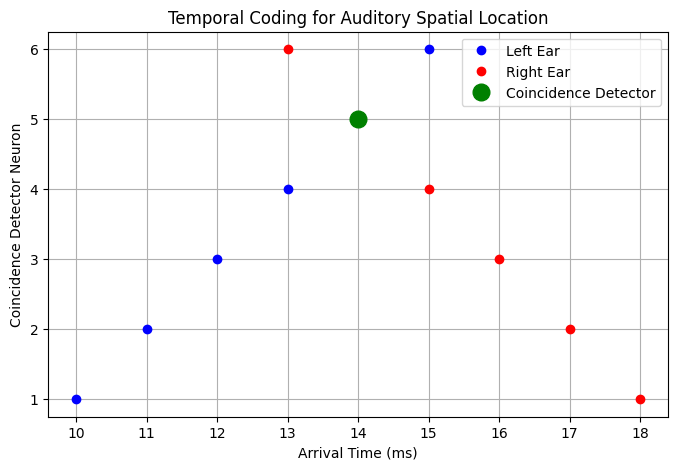


Coincidence detector neurons that fired:
[5]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------
# Temporal Coding: Coincidence Detection
# ----------------------------------

# Sound arrives at left ear first
left_arrival = 10.0   # ms
right_arrival = 13.0  # ms

# Delay lines (different axon lengths)
left_delays = np.array([0, 1, 2, 3, 4, 5])
right_delays = np.array([5, 4, 3, 2, 1, 0])

# Calculate arrival times at each coincidence detector neuron
left_times = left_arrival + left_delays
right_times = right_arrival + right_delays

# Coincidence detection window
threshold = 0.5  # ms

# For summation (memb potential & voltage)
V_rest = 0
V_threshold = 1.5
left_input = 1
right_input = 1

coincident_neurons = []

print("Neuron\tLeft Time\tRight Time\tDifference")

for i in range(len(left_delays)):
    difference = abs(left_times[i] - right_times[i])

    print(f"{i+1}\t{left_times[i]:.1f}\t\t{right_times[i]:.1f}\t\t{difference:.1f}")

    V = V_rest
    V += left_input

    if difference <= threshold:
        V += right_input
    if V >= V_threshold:
        coincident_neurons.append(i + 1)

# Plot timing at each neuron
plt.figure(figsize=(8, 5))

for i in range(len(left_delays)):
    plt.plot(left_times[i], i+1, 'bo', label='Left Ear' if i == 0 else "")
    plt.plot(right_times[i], i+1, 'ro', label='Right Ear' if i == 0 else "")

# Highlight coincidence detectors
for neuron in coincident_neurons:
    plt.plot(left_times[neuron-1], neuron,
             'go', markersize=12,
             label='Coincidence Detector' if neuron == coincident_neurons[0] else "")

plt.xlabel("Arrival Time (ms)")
plt.ylabel("Coincidence Detector Neuron")
plt.title("Temporal Coding for Auditory Spatial Location")
plt.legend()
plt.grid(True)
plt.show()

print("\nCoincidence detector neurons that fired:")
print(coincident_neurons)